# 04 — Model 3: CNN-BiLSTM on Log-Mel Spectrograms
**Owner:** Prakyath S Kumar

**Input:** output of the preprocessing notebook (`logmel.npy`, `segments_meta.csv`, `prep_config.json`) — **Add Input → Your Work → Notebooks** → select it.
**Accelerator:** GPU T4 ×1 (Settings → Accelerator).

**Idea.** A breathing cycle is a sequence in time. A small CNN first turns each short time window of the log-mel spectrogram into a feature vector (local time-frequency patterns such as crackles and wheezes). A **bidirectional LSTM** then reads that sequence of vectors forwards and backwards, so the decision can depend on *how the sound evolves across the whole cycle* — something the plain CNN only captures through pooling.

**Architecture:**
`log-mel (1×64×251) → 3 × ConvBlock → reshape to a time sequence (62 steps) → Linear projection → BiLSTM → mean + max pooling over time → Dropout → Linear(3)`

**Same protocol as Models 1 & 2:** same patient-independent split, same train-only normalisation, same augmentation as the custom CNN (time-roll, SpecAugment masks, light noise), same class-weighted loss, same `evaluate()` metrics, test patients used once.


In [1]:
import os, glob, json, time, copy, random, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score, roc_auc_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
warnings.filterwarnings("ignore")

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
seed_all()
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

INPUT_DIR = os.environ.get("INPUT_DIR", "/kaggle/input")
WORK_DIR  = os.environ.get("WORK_DIR", "/kaggle/working")
FIG_DIR = os.path.join(WORK_DIR, "figures"); os.makedirs(FIG_DIR, exist_ok=True)
EPOCHS = int(os.environ.get("EPOCHS", 40))
RUN_OPTUNA, N_TRIALS = False, 15

def find(name):
    hits = glob.glob(os.path.join(INPUT_DIR, "**", name), recursive=True) + glob.glob(os.path.join(WORK_DIR, name))
    assert hits, f"{name} not found — add the preprocessing notebook output as input"
    return hits[0]

meta = pd.read_csv(find("segments_meta.csv"))
X = np.load(find("logmel.npy")).astype(np.float32)          # (N, 64 mels, 251 frames), dB in [-80, 0]
cfg = json.load(open(find("prep_config.json")))
CLASSES = cfg["classes"]
y = meta["label"].values
tr, va, te = (meta.split == "train").values, (meta.split == "val").values, (meta.split == "test").values
assert not (set(meta.patient[tr]) & set(meta.patient[te])), "patient leakage!"
MU, SD = X[tr].mean(), X[tr].std()                           # normalisation stats from TRAIN only
X = (X - MU) / SD
print(X.shape, {s: int(m.sum()) for s, m in zip(["train", "val", "test"], [tr, va, te])})

device: cuda
(6891, 64, 251) {'train': 4407, 'val': 1650, 'test': 834}


## Dataset with augmentation (identical to the custom CNN, train split only)

In [2]:
class SpecDS(Dataset):
    def __init__(self, X, y, train=False, n_fmask=2, f_w=8, n_tmask=2, t_w=25):
        self.X, self.y, self.train = X, y, train
        self.n_fmask, self.f_w, self.n_tmask, self.t_w = n_fmask, f_w, n_tmask, t_w
    def __len__(self): return len(self.y)
    def __getitem__(self, i):
        x = self.X[i].copy()
        if self.train:
            x = np.roll(x, np.random.randint(x.shape[1]), axis=1)          # random cyclic time shift
            for _ in range(self.n_fmask):                                   # frequency masking
                w = np.random.randint(0, self.f_w + 1); f0 = np.random.randint(0, x.shape[0] - w + 1)
                x[f0:f0 + w, :] = 0
            for _ in range(self.n_tmask):                                   # time masking
                w = np.random.randint(0, self.t_w + 1); t0 = np.random.randint(0, x.shape[1] - w + 1)
                x[:, t0:t0 + w] = 0
            x = x + np.random.randn(*x.shape).astype(np.float32) * 0.05    # light noise
        return torch.from_numpy(x[None]), torch.tensor(self.y[i], dtype=torch.long)

## CNN-BiLSTM architecture
* **ConvBlock** = [Conv 3×3 → BatchNorm → ReLU] × 2 → MaxPool → Dropout2d. Three blocks shrink frequency 64 → 8 but keep enough time resolution (251 → 62 steps).
* **Sequence:** at each of the 62 time steps, the 64 channels × 8 frequency bins (512 values) are flattened and projected to 128 features.
* **BiLSTM** (hidden 64 per direction) reads the 62-step sequence in both directions → 128 features per step.
* **Pooling:** mean over time (overall character of the cycle) concatenated with max over time (strongest short event, e.g. a crackle) → 256 → Linear(3).

In [3]:
class ConvBlock(nn.Module):
    def __init__(self, cin, cout, pool, drop=0.1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
            nn.MaxPool2d(pool), nn.Dropout2d(drop))
    def forward(self, x):
        return self.net(x)

class CNNBiLSTM(nn.Module):
    def __init__(self, n_classes=3, n_mels=64, channels=(24, 48, 64), proj=128, hidden=64, drop=0.3):
        super().__init__()
        c1, c2, c3 = channels
        self.cnn = nn.Sequential(ConvBlock(1, c1, (2, 2)),     # 64x251 -> 32x125
                                 ConvBlock(c1, c2, (2, 2)),    # 32x125 -> 16x62
                                 ConvBlock(c2, c3, (2, 1)))    # 16x62  -> 8x62 (time kept)
        f_out = n_mels // 8
        self.proj = nn.Sequential(nn.Linear(c3 * f_out, proj), nn.ReLU(inplace=True), nn.Dropout(drop))
        self.lstm = nn.LSTM(proj, hidden, num_layers=1, batch_first=True, bidirectional=True)
        self.head = nn.Sequential(nn.Dropout(drop), nn.Linear(4 * hidden, n_classes))
        self.feat = None                                       # last CNN feature map (kept for Grad-CAM)

    def forward(self, x):
        f = self.cnn(x)                                        # (B, C, F', T')
        self.feat = f
        B, C, Fq, T = f.shape
        seq = f.permute(0, 3, 1, 2).reshape(B, T, C * Fq)      # one feature vector per time step
        seq = self.proj(seq)                                   # (B, T', 128)
        out, _ = self.lstm(seq)                                # (B, T', 2*hidden)
        pooled = torch.cat([out.mean(1), out.max(1).values], dim=1)
        return self.head(pooled)

m = CNNBiLSTM(n_mels=X.shape[1])
print(m)
print("trainable parameters:", sum(p.numel() for p in m.parameters() if p.requires_grad))
with torch.no_grad():
    print("output shape check:", m(torch.zeros(2, 1, X.shape[1], X.shape[2])).shape)

CNNBiLSTM(
  (cnn): Sequential(
    (0): ConvBlock(
      (net): Sequential(
        (0): Conv2d(1, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): BatchNorm2d(24, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (5): ReLU(inplace=True)
        (6): MaxPool2d(kernel_size=(2, 2), stride=(2, 2), padding=0, dilation=1, ceil_mode=False)
        (7): Dropout2d(p=0.1, inplace=False)
      )
    )
    (1): ConvBlock(
      (net): Sequential(
        (0): Conv2d(24, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(48, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(48, 48, kernel_size=(3, 3), stride=(1, 1), padding=(1,

## Common evaluation helper (identical to Models 1 & 2)

In [4]:
def evaluate(y_true, prob, patients=None, name="model"):
    pred = prob.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    res = dict(model=name, acc=accuracy_score(y_true, pred), macro_precision=p, macro_recall=r, macro_f1=f)
    yb, pb, predb = (y_true != 0).astype(int), 1 - prob[:, 0], (pred != 0).astype(int)
    tn, fp, fn, tp = confusion_matrix(yb, predb, labels=[0, 1]).ravel()
    res.update(sensitivity=tp / max(tp + fn, 1), specificity=tn / max(tn + fp, 1),
               binary_f1=f1_score(yb, predb, zero_division=0),
               auroc=roc_auc_score(yb, pb) if len(set(yb)) > 1 else float("nan"))
    if patients is not None:
        dfp = pd.DataFrame(prob).assign(patient=patients, y=y_true).groupby("patient").mean()
        pp, yp = dfp[[0, 1, 2]].values, dfp["y"].values.astype(int)
        res.update(patient_acc=accuracy_score(yp, pp.argmax(1)),
                   patient_macro_f1=f1_score(yp, pp.argmax(1), average="macro", zero_division=0))
    return {k: (round(float(v), 4) if not isinstance(v, str) else v) for k, v in res.items()}

## Training loop (early stopping on validation macro-F1; gradient clipping for the LSTM)

In [5]:
@torch.no_grad()
def predict(model, Xa, bs=256):
    model.eval(); out = []
    for i in range(0, len(Xa), bs):
        xb = torch.from_numpy(Xa[i:i + bs][:, None]).to(DEVICE)
        with torch.autocast(device_type="cuda", enabled=DEVICE == "cuda"):
            out.append(F.softmax(model(xb).float(), 1).cpu().numpy())
    return np.concatenate(out)

def train_model(hp, epochs=EPOCHS, patience=10, verbose=True):
    seed_all()
    model = CNNBiLSTM(n_mels=X.shape[1], hidden=hp["hidden"], drop=hp["drop"]).to(DEVICE)
    cw = compute_class_weight("balanced", classes=np.arange(3), y=y[tr]) ** hp["cw_power"]
    crit = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32, device=DEVICE), label_smoothing=0.05)
    opt = torch.optim.AdamW(model.parameters(), lr=hp["lr"], weight_decay=hp["wd"])
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    scaler = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")
    dl = DataLoader(SpecDS(X[tr], y[tr], train=True, f_w=hp["f_w"], t_w=hp["t_w"]), batch_size=hp["bs"],
                    shuffle=True, num_workers=2, drop_last=True)
    hist, best_f1, best_state, bad = [], -1, None, 0
    for ep in range(epochs):
        model.train(); t0, tot, n = time.time(), 0.0, 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad()
            with torch.autocast(device_type="cuda", enabled=DEVICE == "cuda"):
                loss = crit(model(xb), yb)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)       # keeps LSTM gradients stable
            scaler.step(opt); scaler.update()
            tot += loss.item() * len(yb); n += len(yb)
        sched.step()
        pv = predict(model, X[va])
        vf1 = f1_score(y[va], pv.argmax(1), average="macro")
        vloss = F.nll_loss(torch.log(torch.tensor(pv) + 1e-8), torch.tensor(y[va])).item()
        hist.append(dict(epoch=ep + 1, train_loss=tot / n, val_loss=vloss,
                         val_acc=accuracy_score(y[va], pv.argmax(1)), val_macro_f1=vf1))
        if verbose:
            print(f"ep {ep+1:02d} | train loss {hist[-1]['train_loss']:.4f} | val loss {vloss:.4f} "
                  f"| val acc {hist[-1]['val_acc']:.4f} | val macro-F1 {vf1:.4f} | {time.time()-t0:.1f}s")
        if vf1 > best_f1:
            best_f1, best_state, bad = vf1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= patience:
                if verbose: print("early stopping")
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), best_f1

DEFAULT_HP = dict(hidden=64, drop=0.3, lr=1e-3, wd=1e-3, bs=64, f_w=8, t_w=25, cw_power=1.0)

## (Optional) Optuna hyperparameter search — maximises validation macro-F1 (off by default, as for the CNN)

In [6]:
hp = dict(DEFAULT_HP)
if RUN_OPTUNA:
    import optuna
    def objective(trial):
        h = dict(hidden=trial.suggest_categorical("hidden", [32, 64, 96]),
                 drop=trial.suggest_float("drop", 0.1, 0.5),
                 lr=trial.suggest_float("lr", 2e-4, 3e-3, log=True), wd=trial.suggest_float("wd", 1e-5, 1e-2, log=True),
                 bs=trial.suggest_categorical("bs", [32, 64]), f_w=trial.suggest_int("f_w", 4, 12),
                 t_w=trial.suggest_int("t_w", 10, 40), cw_power=trial.suggest_float("cw_power", 0.5, 1.0))
        return train_model(h, epochs=15, patience=5, verbose=False)[2]
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS)
    hp.update(study.best_params)
    study.trials_dataframe().to_csv(os.path.join(WORK_DIR, "optuna_trials_cnn_bilstm.csv"), index=False)
    print("best:", study.best_value, study.best_params)
print("using hyperparameters:", hp)

using hyperparameters: {'hidden': 64, 'drop': 0.3, 'lr': 0.001, 'wd': 0.001, 'bs': 64, 'f_w': 8, 't_w': 25, 'cw_power': 1.0}


In [7]:
model, hist, best_val = train_model(hp)
torch.save(model.state_dict(), os.path.join(WORK_DIR, "cnn_bilstm_best.pt"))
hist.to_csv(os.path.join(WORK_DIR, "cnn_bilstm_training_history.csv"), index=False)
print("best val macro-F1:", round(best_val, 4), "| best epoch:", int(hist.val_macro_f1.idxmax()) + 1, "of", len(hist))

ep 01 | train loss 1.2284 | val loss 0.9950 | val acc 0.5721 | val macro-F1 0.2710 | 5.6s
ep 02 | train loss 1.1753 | val loss 1.1213 | val acc 0.3655 | val macro-F1 0.2156 | 3.2s
ep 03 | train loss 1.1482 | val loss 1.2576 | val acc 0.3806 | val macro-F1 0.2756 | 3.2s
ep 04 | train loss 1.1124 | val loss 0.9888 | val acc 0.6558 | val macro-F1 0.3843 | 3.2s
ep 05 | train loss 1.0717 | val loss 1.0187 | val acc 0.5661 | val macro-F1 0.3525 | 3.2s
ep 06 | train loss 1.0613 | val loss 0.8884 | val acc 0.7024 | val macro-F1 0.3921 | 3.2s
ep 07 | train loss 1.0271 | val loss 1.1278 | val acc 0.5345 | val macro-F1 0.3327 | 3.2s
ep 08 | train loss 1.0089 | val loss 1.0598 | val acc 0.5606 | val macro-F1 0.3622 | 3.2s
ep 09 | train loss 0.9933 | val loss 0.9121 | val acc 0.6333 | val macro-F1 0.3963 | 3.2s
ep 10 | train loss 0.9795 | val loss 0.8669 | val acc 0.7109 | val macro-F1 0.4324 | 3.2s
ep 11 | train loss 0.9559 | val loss 0.8846 | val acc 0.6642 | val macro-F1 0.4140 | 3.2s
ep 12 | tr

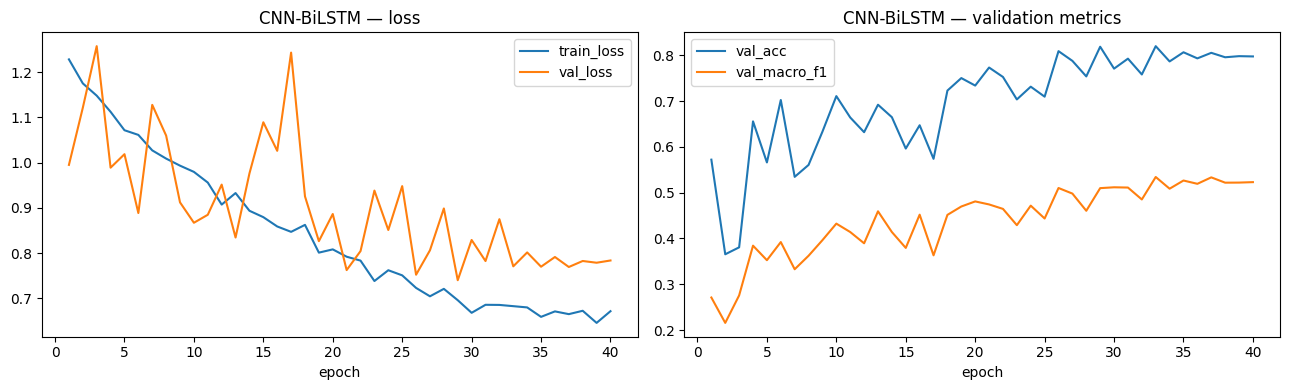

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
hist.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax[0], title="CNN-BiLSTM — loss")
hist.plot(x="epoch", y=["val_acc", "val_macro_f1"], ax=ax[1], title="CNN-BiLSTM — validation metrics")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "cnn_bilstm_learning_curves.png"), dpi=130); plt.show()

## Test evaluation (held-out patients, used once)

model             CNN-BiLSTM
acc                   0.8741
macro_precision       0.7024
macro_recall          0.7689
macro_f1              0.7123
sensitivity           0.9687
specificity           0.5354
binary_f1             0.9538
auroc                 0.7186
patient_acc           0.8333
patient_macro_f1      0.8381
              precision    recall  f1-score   support

     Healthy       0.70      0.54      0.61        99
     Chronic       0.96      0.93      0.94       683
 Non-chronic       0.45      0.85      0.59        52

    accuracy                           0.87       834
   macro avg       0.70      0.77      0.71       834
weighted avg       0.89      0.87      0.88       834



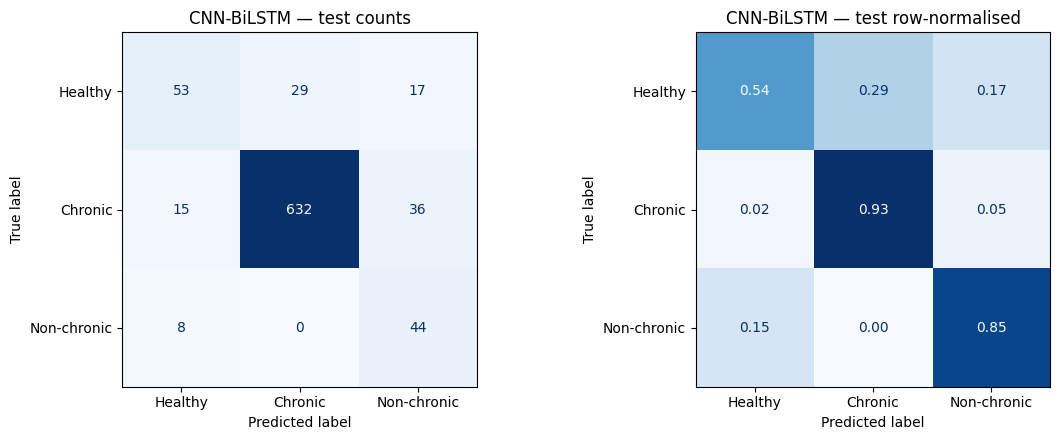

In [9]:
prob = predict(model, X[te])
res = evaluate(y[te], prob, meta.patient.values[te], "CNN-BiLSTM")
res_df = pd.DataFrame([res]).set_index("model")
print(res_df.T)
print(classification_report(y[te], prob.argmax(1), labels=range(3), target_names=CLASSES, zero_division=0))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y[te], prob.argmax(1), labels=range(3)),
                       display_labels=CLASSES).plot(cmap="Blues", ax=ax[0], colorbar=False)
ax[0].set_title("CNN-BiLSTM — test counts")
ConfusionMatrixDisplay(confusion_matrix(y[te], prob.argmax(1), labels=range(3), normalize="true"),
                       display_labels=CLASSES).plot(cmap="Blues", values_format=".2f", ax=ax[1], colorbar=False)
ax[1].set_title("CNN-BiLSTM — test row-normalised")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "cm_cnn_bilstm.png"), dpi=130); plt.show()

## Error analysis (by recording device, cycle annotation and diagnosis)

In [10]:
ev = meta[te].assign(pred=prob.argmax(1), conf=prob.max(1))
ev["correct"] = ev.pred == ev.label
print("Accuracy by device:\n", ev.groupby("device").correct.agg(["mean", "size"]).round(3))
print("\nAccuracy by cycle annotation:\n", ev.groupby("cycle_label").correct.agg(["mean", "size"]).round(3))
print("\nAccuracy by diagnosis:\n", ev.groupby("diagnosis").correct.agg(["mean", "size"]).round(3))
print("\nMean confidence — correct vs wrong:\n", ev.groupby("correct").conf.mean().round(3))
ev.to_csv(os.path.join(WORK_DIR, "cnn_bilstm_test_predictions.csv"), index=False)

Accuracy by device:
            mean  size
device               
AKGC417L  0.923   611
Litt3200  1.000    61
LittC2SE  0.636    11
Meditron  0.642   151

Accuracy by cycle annotation:
               mean  size
cycle_label             
both         0.939    66
crackle      0.980   203
normal       0.812   474
wheeze       0.912    91

Accuracy by diagnosis:
             mean  size
diagnosis             
COPD       0.925   683
Healthy    0.535    99
LRTI       0.917    24
URTI       0.786    28

Mean confidence — correct vs wrong:
 correct
False    0.651
True     0.701
Name: conf, dtype: float32


## Explainability: Grad-CAM on the last CNN block
Gradient of the predicted class score with respect to the last CNN feature map (64 channels × 8 freq × 62 time), averaged per channel to get channel weights, weighted sum → ReLU → upsampled to 64×251. Shows which time–frequency regions drove the decision. (cuDNN is switched off for this step only, because cuDNN's LSTM cannot back-propagate in eval mode.)

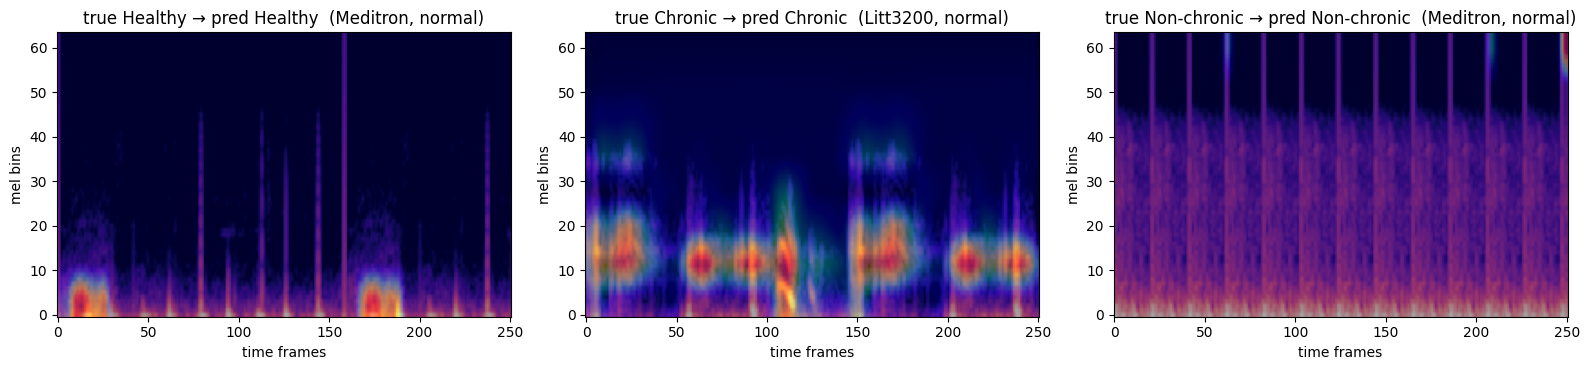

In [11]:
def gradcam(model, x, target=None):
    model.eval()
    x = torch.from_numpy(x[None, None]).to(DEVICE)
    with torch.backends.cudnn.flags(enabled=False):
        logits = model(x)
        target = int(logits.argmax(1)) if target is None else target
        g = torch.autograd.grad(logits[0, target], model.feat)[0]      # (1, C, F', T')
    A = model.feat.detach()
    w = g.mean(dim=(2, 3), keepdim=True)
    cam = F.relu((w * A).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0].cpu().numpy()
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    return cam, target

te_idx = np.flatnonzero(te)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for k, c in enumerate(CLASSES):
    ok = te_idx[(y[te_idx] == k) & (prob.argmax(1) == k)]               # a correctly classified example
    cand = ok if len(ok) else te_idx[y[te_idx] == k]
    i = int(cand[0])
    cam, t = gradcam(model, X[i])
    ax[k].imshow(X[i], origin="lower", aspect="auto", cmap="magma")
    ax[k].imshow(cam, origin="lower", aspect="auto", cmap="jet", alpha=0.35)
    ax[k].set_title(f"true {c} → pred {CLASSES[t]}  ({meta.device[i]}, {meta.cycle_label[i]})")
    ax[k].set_xlabel("time frames"); ax[k].set_ylabel("mel bins")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "gradcam_cnn_bilstm.png"), dpi=130); plt.show()

## Comparison table (common protocol)
Loads the saved result files of Model 1 (classical) and Model 2 (CNN) **if they are attached as inputs**; otherwise uses the values printed in those notebooks' saved outputs. An *always-Chronic* reference predictor is added so accuracy can be read against the majority baseline. The attention Transformer is not included here because its notebook reports a different metric set.

In [12]:
def load_or(filename, fallback_rows):
    hits = glob.glob(os.path.join(INPUT_DIR, "**", filename), recursive=True)
    if hits:
        print("loaded", hits[0]); return pd.read_csv(hits[0]).set_index("model")
    print(f"{filename} not attached — using values from that notebook's saved output")
    return pd.DataFrame(fallback_rows).set_index("model")

cols = ["model", "acc", "macro_precision", "macro_recall", "macro_f1", "sensitivity", "specificity",
        "binary_f1", "auroc", "patient_acc", "patient_macro_f1"]
classical = load_or("results_model1_classical.csv", [
    dict(zip(cols, ["SVM (RBF)",     0.8945, 0.7727, 0.7083, 0.6787, 0.9932, 0.2727, 0.9499, 0.9172, 0.6667, 0.6556])),
    dict(zip(cols, ["Random Forest", 0.8645, 0.8022, 0.5465, 0.5738, 0.9973, 0.1010, 0.9416, 0.8760, 0.4444, 0.4485])),
    dict(zip(cols, ["XGBoost",       0.8945, 0.7794, 0.6824, 0.6544, 0.9946, 0.1818, 0.9451, 0.9166, 0.5556, 0.5242]))])
cnn = load_or("results_model2_cnn.csv", [
    dict(zip(cols, ["Custom CNN (ResDS)", 0.7974, 0.5866, 0.6204, 0.5671, 0.9633, 0.3939, 0.9421, 0.6922, 0.6667, 0.6429]))])

always_chronic = np.zeros((te.sum(), 3)); always_chronic[:, 1] = 1.0
baseline = pd.DataFrame([evaluate(y[te], always_chronic, meta.patient.values[te], "Always-Chronic reference")]).set_index("model")

comparison = pd.concat([classical, cnn, res_df, baseline])
comparison.to_csv(os.path.join(WORK_DIR, "comparison_with_cnn_bilstm.csv"))
res_df.to_csv(os.path.join(WORK_DIR, "results_model3_cnn_bilstm.csv"))
print(comparison.to_string())

results_model1_classical.csv not attached — using values from that notebook's saved output
results_model2_cnn.csv not attached — using values from that notebook's saved output
                             acc  macro_precision  macro_recall  macro_f1  sensitivity  specificity  binary_f1   auroc  patient_acc  patient_macro_f1
model                                                                                                                                                
SVM (RBF)                 0.8945           0.7727        0.7083    0.6787       0.9932       0.2727     0.9499  0.9172       0.6667            0.6556
Random Forest             0.8645           0.8022        0.5465    0.5738       0.9973       0.1010     0.9416  0.8760       0.4444            0.4485
XGBoost                   0.8945           0.7794        0.6824    0.6544       0.9946       0.1818     0.9451  0.9166       0.5556            0.5242
Custom CNN (ResDS)        0.7974           0.5866        0.6204    0.5671 

## Robustness check: 5 random seeds (same model, same data, same split)
The main result above is a **single run with seed 42**, like every other model in the comparison table, so the table stays like-for-like.
This section asks a different question: *how much does the result depend on the random seed?* The **identical** CNN-BiLSTM, hyperparameters, augmentation, loss and early-stopping rule are trained 5 times; only the seed changes (it controls the initial weights, augmentation randomness and batch order). Each run picks its best epoch on **validation only**; the test patients are still never used for any decision.
Reported: each seed's test metrics, their **mean ± std**, and (separately labelled) the average-probability **ensemble** of the 5 runs. These are **not** placed in the main comparison table, because the other models were each trained once.

In [13]:
SEEDS = [42, 7, 123, 2024, 31]
_seed_all_original = seed_all

def train_with_seed(seed):
    # train_model() calls seed_all() at its start; point it at this run's seed, then restore the original.
    global seed_all
    seed_all = lambda s=seed: _seed_all_original(s)
    try:
        return train_model(hp, verbose=False)
    finally:
        seed_all = _seed_all_original

seed_rows, seed_probs = [], []
for s in SEEDS:
    t0 = time.time()
    m_s, h_s, v_s = train_with_seed(s)
    p_s = predict(m_s, X[te])
    seed_probs.append(p_s)
    r = evaluate(y[te], p_s, meta.patient.values[te], f"seed {s}")
    r.update(best_val_macro_f1=round(float(v_s), 4), best_epoch=int(h_s.val_macro_f1.idxmax()) + 1)
    seed_rows.append(r)
    print(f"seed {s:>4}: val macro-F1 {v_s:.4f} | test macro-F1 {r['macro_f1']:.4f} | "
          f"specificity {r['specificity']:.4f} | AUROC {r['auroc']:.4f} | best epoch {r['best_epoch']} | {time.time()-t0:.0f}s")
    del m_s
    if DEVICE == "cuda": torch.cuda.empty_cache()

seed   42: val macro-F1 0.5342 | test macro-F1 0.7123 | specificity 0.5354 | AUROC 0.7186 | best epoch 33 | 140s
seed    7: val macro-F1 0.5414 | test macro-F1 0.6387 | specificity 0.3636 | AUROC 0.7418 | best epoch 18 | 98s
seed  123: val macro-F1 0.5794 | test macro-F1 0.7000 | specificity 0.4949 | AUROC 0.7314 | best epoch 35 | 140s
seed 2024: val macro-F1 0.5736 | test macro-F1 0.7233 | specificity 0.4545 | AUROC 0.6945 | best epoch 35 | 140s
seed   31: val macro-F1 0.6065 | test macro-F1 0.7109 | specificity 0.4040 | AUROC 0.7162 | best epoch 29 | 137s


In [14]:
seeds_df = pd.DataFrame(seed_rows).set_index("model")
metric_cols = ["acc", "macro_precision", "macro_recall", "macro_f1", "sensitivity", "specificity",
               "binary_f1", "auroc", "patient_acc", "patient_macro_f1", "best_val_macro_f1"]
summary = pd.DataFrame({"mean": seeds_df[metric_cols].mean(), "std": seeds_df[metric_cols].std(ddof=1)}).round(4)
summary["mean ± std"] = summary["mean"].map("{:.4f}".format) + " ± " + summary["std"].map("{:.4f}".format)

ens_prob = np.mean(seed_probs, axis=0)
ens = pd.DataFrame([evaluate(y[te], ens_prob, meta.patient.values[te], "5-seed ensemble (avg. probabilities)")]).set_index("model")

print("Per-seed test results:")
print(seeds_df.to_string())
print("\nMean ± std over the 5 seeds:")
print(summary[["mean ± std"]].to_string())
print("\nEnsemble of the 5 seeds (reported separately, not in the main table):")
print(ens.T.to_string())

seeds_df.to_csv(os.path.join(WORK_DIR, "cnn_bilstm_seed_runs.csv"))
summary.to_csv(os.path.join(WORK_DIR, "cnn_bilstm_seed_summary.csv"))
ens.to_csv(os.path.join(WORK_DIR, "cnn_bilstm_seed_ensemble.csv"))

Per-seed test results:
              acc  macro_precision  macro_recall  macro_f1  sensitivity  specificity  binary_f1   auroc  patient_acc  patient_macro_f1  best_val_macro_f1  best_epoch
model                                                                                                                                                                
seed 42    0.8741           0.7024        0.7689    0.7123       0.9687       0.5354     0.9538  0.7186       0.8333            0.8381             0.5342          33
seed 7     0.8477           0.6666        0.6797    0.6387       0.9769       0.3636     0.9472  0.7418       0.6667            0.6877             0.5414          18
seed 123   0.8741           0.7111        0.7456    0.7000       0.9782       0.4949     0.9561  0.7314       0.8333            0.8381             0.5794          35
seed 2024  0.8945           0.7348        0.7542    0.7233       0.9755       0.4545     0.9522  0.6945       0.7778            0.7738             

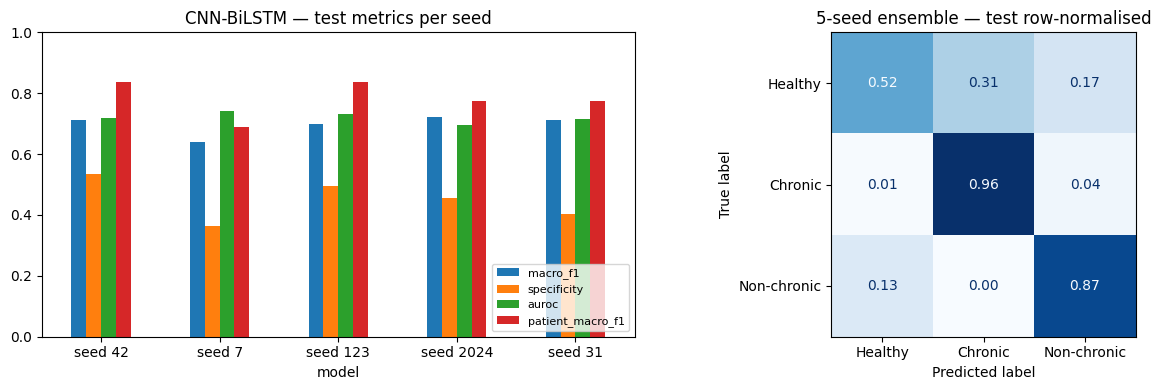

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
show = ["macro_f1", "specificity", "auroc", "patient_macro_f1"]
seeds_df[show].plot.bar(ax=ax[0], rot=0)
ax[0].set_title("CNN-BiLSTM — test metrics per seed"); ax[0].set_ylim(0, 1); ax[0].legend(loc="lower right", fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(y[te], ens_prob.argmax(1), labels=range(3), normalize="true"),
                       display_labels=CLASSES).plot(cmap="Blues", values_format=".2f", ax=ax[1], colorbar=False)
ax[1].set_title("5-seed ensemble — test row-normalised")
plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, "cnn_bilstm_seed_robustness.png"), dpi=130); plt.show()